## Correlación Canónica y Análisis Factorial
### Ejemplo y actividad

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_iris, load_breast_cancer, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.cross_decomposition import CCA
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score, roc_auc_score

import statsmodels.api as sm
from scipy import stats

%matplotlib inline
sns.set_style('whitegrid')

In [2]:
# ============================================================
# EJEMPLO 1: ANÁLISIS DE CORRELACIÓN CANÓNICA (CCA)
# ============================================================

# Dataset Iris: medimos dos conjuntos de variables
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris.columns = ['Long_Sepalo', 'Ancho_Sepalo', 'Long_Petalo', 'Ancho_Petalo']

# Conjunto X: sépalos. Conjunto Y: pétalos
X_cca = df_iris[['Long_Sepalo', 'Ancho_Sepalo']].values
Y_cca = df_iris[['Long_Petalo', 'Ancho_Petalo']].values

print("Conjunto X (sépalos):", X_cca.shape)
print("Conjunto Y (pétalos):", Y_cca.shape)
print("\nPrimeras filas:")
df_iris.head()

Conjunto X (sépalos): (150, 2)
Conjunto Y (pétalos): (150, 2)

Primeras filas:


,Long_Sepalo,Ancho_Sepalo,Long_Petalo,Ancho_Petalo
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
# Estandarizar antes de CCA
scaler = StandardScaler()
X_cca_std = scaler.fit_transform(X_cca)
Y_cca_std = scaler.fit_transform(Y_cca)

# Ajustar CCA con 2 componentes
cca = CCA(n_components=2)
U, V = cca.fit_transform(X_cca_std, Y_cca_std)

# Correlaciones canónicas
rho = [np.corrcoef(U[:, i], V[:, i])[0, 1] for i in range(2)]
print("Correlaciones canónicas:")
for i, r in enumerate(rho):
    print(f"  ρ_{i+1} = {r:.4f}  (ρ² = {r**2:.4f})")

Correlaciones canónicas:
  ρ_1 = 0.9410  (ρ² = 0.8854)
  ρ_2 = 0.1239  (ρ² = 0.0154)


In [4]:
# Pesos canónicos (coeficientes)
pesos_X = pd.DataFrame(cca.x_weights_,
                        index=['Long_Sepalo', 'Ancho_Sepalo'],
                        columns=['U1', 'U2'])
pesos_Y = pd.DataFrame(cca.y_weights_,
                        index=['Long_Petalo', 'Ancho_Petalo'],
                        columns=['V1', 'V2'])

print("Pesos canónicos para X (sépalos):")
print(pesos_X.round(4))
print("\nPesos canónicos para Y (pétalos):")
print(pesos_Y.round(4))

# Cargas canónicas (correlación entre variable original y variable canónica)
cargas_X = pd.DataFrame(
    [np.corrcoef(X_cca_std[:, j], U[:, i])[0, 1]
     for i in range(2) for j in range(2)],
    index=['U1-Long_Sepalo', 'U1-Ancho_Sepalo', 'U2-Long_Sepalo', 'U2-Ancho_Sepalo'],
    columns=['Carga']
)
print("\nCargas canónicas para X:")
print(cargas_X.round(4))

Pesos canónicos para X (sépalos):
                  U1      U2
Long_Sepalo   0.9217  0.3880
Ancho_Sepalo -0.3880  0.9217

Pesos canónicos para Y (pétalos):
                  V1      V2
Long_Petalo   0.9430  0.3327
Ancho_Petalo -0.3327  0.9430

Cargas canónicas para X:
                  Carga
U1-Long_Sepalo   0.9290
U1-Ancho_Sepalo -0.4767
U2-Long_Sepalo   0.3701
U2-Ancho_Sepalo  0.8791


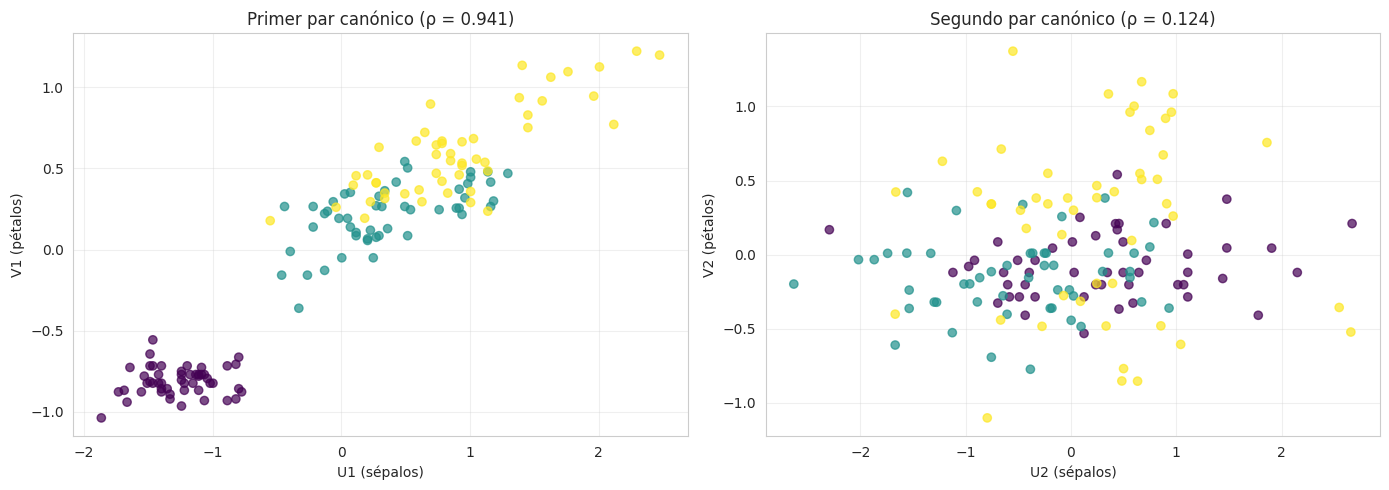

In [5]:
# Scatter de las variables canónicas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par canónico 1
axes[0].scatter(U[:, 0], V[:, 0], c=iris.target, cmap='viridis', alpha=0.7)
axes[0].set_xlabel('U1 (sépalos)')
axes[0].set_ylabel('V1 (pétalos)')
axes[0].set_title(f'Primer par canónico (ρ = {rho[0]:.3f})')
axes[0].grid(True, alpha=0.3)

# Par canónico 2
axes[1].scatter(U[:, 1], V[:, 1], c=iris.target, cmap='viridis', alpha=0.7)
axes[1].set_xlabel('U2 (sépalos)')
axes[1].set_ylabel('V2 (pétalos)')
axes[1].set_title(f'Segundo par canónico (ρ = {rho[1]:.3f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# PARTE 2: ANÁLISIS FACTORIAL (AF)
# ============================================================

# Dataset Breast Cancer: 30 variables correlacionadas
data_bc = load_breast_cancer()
X_bc = pd.DataFrame(data_bc.data, columns=data_bc.feature_names)
y_bc = data_bc.target

print(f"Forma del dataset: {X_bc.shape}")
print(f"Variables: {X_bc.shape[1]}")
print(f"\nPrimeras variables:")
print(list(X_bc.columns[:10]))

Forma del dataset: (569, 30)
Variables: 30

Primeras variables:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']


In [7]:
# Seleccionar 10 variables representativas (evitar multicolinealidad extrema)
vars_fa = ['mean radius', 'mean texture', 'mean perimeter',
           'mean area', 'mean smoothness', 'mean compactness',
           'mean concavity', 'mean concave points',
           'mean symmetry', 'mean fractal dimension']

X_fa = X_bc[vars_fa].values
X_fa_std = StandardScaler().fit_transform(X_fa)

print(f"Variables seleccionadas: {len(vars_fa)}")
print(f"Forma: {X_fa_std.shape}")

Variables seleccionadas: 10
Forma: (569, 10)


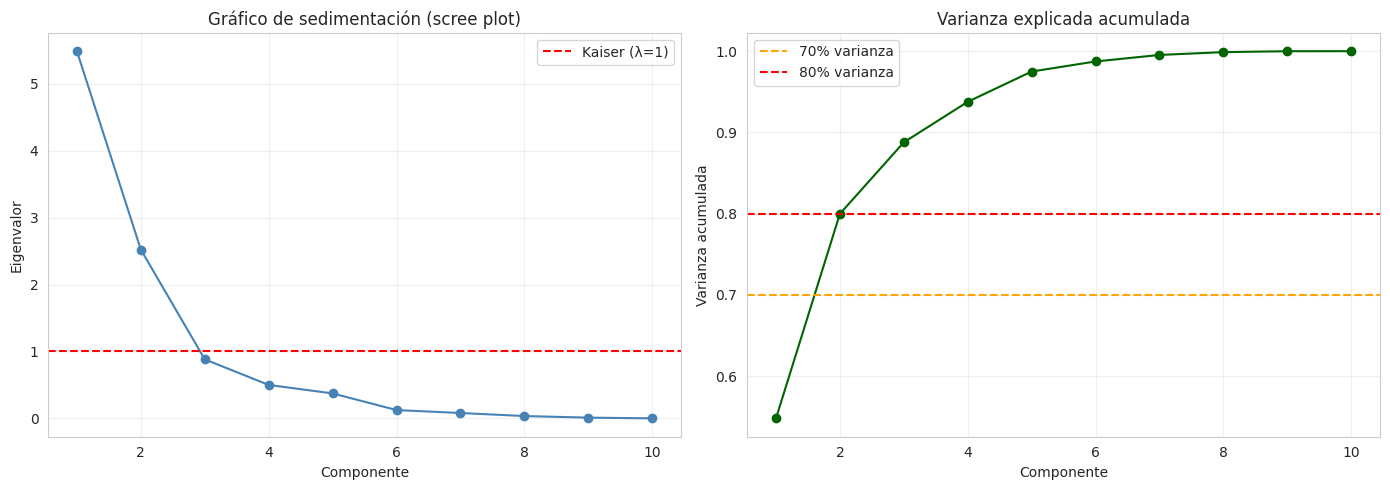


Factores con eigenvalor > 1: 2
Varianza acumulada con 2 factores: 0.800


In [8]:
# Gráfico de sedimentación (scree plot)
pca_temp = PCA()
pca_temp.fit(X_fa_std)
eigenvalues = pca_temp.explained_variance_
varianza_acum = np.cumsum(pca_temp.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, 'o-', color='steelblue')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Eigenvalor')
axes[0].set_title('Gráfico de sedimentación (scree plot)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Varianza acumulada
axes[1].plot(range(1, len(varianza_acum) + 1), varianza_acum, 'o-', color='darkgreen')
axes[1].axhline(y=0.7, color='orange', linestyle='--', label='70% varianza')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% varianza')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title('Varianza explicada acumulada')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Regla de Kaiser
n_factores = sum(eigenvalues > 1)
print(f"\nFactores con eigenvalor > 1: {n_factores}")
print(f"Varianza acumulada con {n_factores} factores: {varianza_acum[n_factores-1]:.3f}")

In [9]:
# Extraer factores con FactorAnalysis (máxima verosimilitud)
fa = FactorAnalysis(n_components=n_factores, random_state=42)
scores_fa = fa.fit_transform(X_fa_std)

# Cargas factoriales
cargas_fa = pd.DataFrame(fa.components_.T,
                          index=vars_fa,
                          columns=[f'F{i+1}' for i in range(n_factores)])

print("Cargas factoriales:")
print(cargas_fa.round(3))

Cargas factoriales:
                           F1     F2
mean radius             0.998 -0.053
mean texture            0.329  0.060
mean perimeter          1.000  0.007
mean area               0.987 -0.044
mean smoothness         0.203  0.679
mean compactness        0.551  0.814
mean concavity          0.712  0.615
mean concave points     0.848  0.458
mean symmetry           0.179  0.619
mean fractal dimension -0.267  0.866


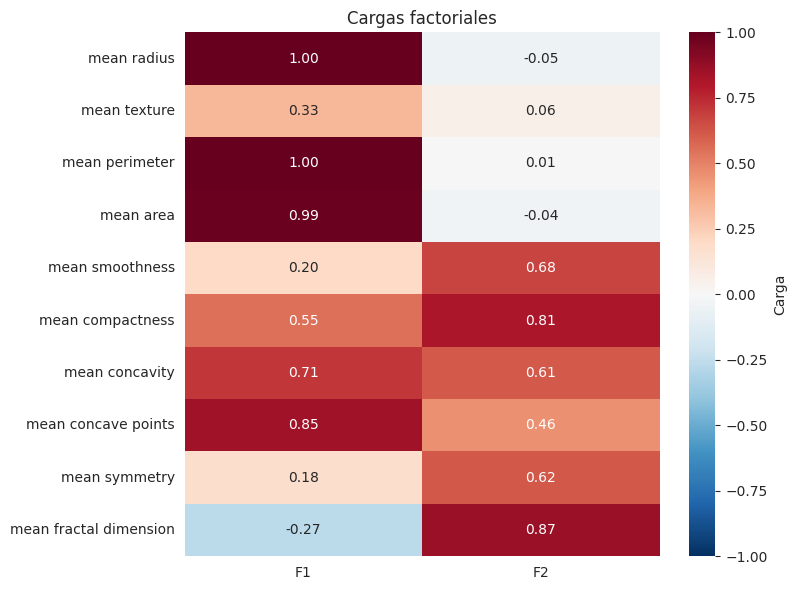


Comunalidades (varianza explicada por factores):
mean radius               0.999
mean texture              0.112
mean perimeter            1.000
mean area                 0.976
mean smoothness           0.502
mean compactness          0.967
mean concavity            0.884
mean concave points       0.929
mean symmetry             0.415
mean fractal dimension    0.821
dtype: float64


In [10]:
# Heatmap de cargas factoriales
plt.figure(figsize=(8, 6))
sns.heatmap(cargas_fa, annot=True, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, fmt='.2f', cbar_kws={'label': 'Carga'})
plt.title('Cargas factoriales')
plt.tight_layout()
plt.show()

# Comunalidades (proporción de varianza explicada por los factores)
comunalidades = (cargas_fa ** 2).sum(axis=1)
print("\nComunalidades (varianza explicada por factores):")
print(comunalidades.round(3))

In [11]:
# ============================================================
# EJEMPLO 3: ANÁLISIS FACTORIAL APLICADO A REGRESIÓN
# ============================================================

# Usamos los scores factoriales como predictores
# Objetivo: clasificar si el tumor es benigno o maligno

# Modelo 1: regresión con variables originales (multicolinealidad)
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_fa_std, y_bc, test_size=0.3, random_state=42, stratify=y_bc
)

modelo_orig = LogisticRegression(max_iter=1000, random_state=42)
modelo_orig.fit(X_train_orig, y_train)
acc_orig = accuracy_score(y_test, modelo_orig.predict(X_test_orig))

# Modelo 2: regresión con scores factoriales
X_train_fa, X_test_fa, _, _ = train_test_split(
    scores_fa, y_bc, test_size=0.3, random_state=42, stratify=y_bc
)

modelo_fa = LogisticRegression(max_iter=1000, random_state=42)
modelo_fa.fit(X_train_fa, y_train)
acc_fa = accuracy_score(y_test, modelo_fa.predict(X_test_fa))

print("=== COMPARACIÓN DE MODELOS ===\n")
print(f"Modelo con variables originales ({X_fa.shape[1]} vars):")
print(f"  Accuracy: {acc_orig:.4f}")
print(f"\nModelo con factores ({n_factores} factores):")
print(f"  Accuracy: {acc_fa:.4f}")
print(f"\nReducción de dimensionalidad: {X_fa.shape[1]} → {n_factores}")

=== COMPARACIÓN DE MODELOS ===

Modelo con variables originales (10 vars):
  Accuracy: 0.9181

Modelo con factores (2 factores):
  Accuracy: 0.9181

Reducción de dimensionalidad: 10 → 2


In [12]:
# ============================================================
# ACTIVIDAD: REPLICAR TODO CON EL DATASET DE VINOS
# ============================================================

print("ACTIVIDAD: Correlación Canónica y Análisis Factorial")
print("=" * 55)
print("\nDataset: Wine (load_wine)")
print("\nInstrucciones:")
print("\n1. CCA:")
print("   - Definir dos conjuntos de variables de vino.")
print("     Ejemplo: X = alcalinidad, magnesio, fenoles totales")
print("              Y = alcohol, ácido málico, ceniza")
print("   - Estandarizar ambos conjuntos")
print("   - Ajustar CCA con 2 componentes")
print("   - Reportar correlaciones canónicas")
print("   - Graficar pares canónicos")
print()
print("2. Análisis Factorial:")
print("   - Seleccionar 8-10 variables del dataset")
print("   - Estandarizar")
print("   - Scree plot para elegir número de factores")
print("   - Extraer factores y reportar cargas")
print("   - Interpretar los factores")
print()
print("3. FA + Regresión:")
print("   - Binificar la variable Clase (ej. 0 vs resto)")
print("   - Ajustar regresión logística con variables originales")
print("   - Ajustar regresión logística con scores factoriales")
print("   - Comparar accuracy de ambos modelos")

ACTIVIDAD: Correlación Canónica y Análisis Factorial

Dataset: Wine (load_wine)

Instrucciones:

1. CCA:
   - Definir dos conjuntos de variables de vino.
     Ejemplo: X = alcalinidad, magnesio, fenoles totales
              Y = alcohol, ácido málico, ceniza
   - Estandarizar ambos conjuntos
   - Ajustar CCA con 2 componentes
   - Reportar correlaciones canónicas
   - Graficar pares canónicos

2. Análisis Factorial:
   - Seleccionar 8-10 variables del dataset
   - Estandarizar
   - Scree plot para elegir número de factores
   - Extraer factores y reportar cargas
   - Interpretar los factores

3. FA + Regresión:
   - Binificar la variable Clase (ej. 0 vs resto)
   - Ajustar regresión logística con variables originales
   - Ajustar regresión logística con scores factoriales
   - Comparar accuracy de ambos modelos


In [ ]:
# ============================================================
# PLANTILLA PARA LA ACTIVIDAD (COMPLETAR)
# ============================================================

# 1. CARGAR DATOS
# wine = load_wine()
# X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
# y_wine = pd.Series(wine.target, name='Clase')
# df_wine = pd.concat([X_wine, y_wine], axis=1)

# 2. CCA - Definir conjuntos
# X_cca_w = df_wine[['alcalinity_of_ash', 'magnesium', 'total_phenols']].values
# Y_cca_w = df_wine[['alcohol', 'malic_acid', 'ash']].values

# 3. CCA - Estandarizar y ajustar
# X_cca_w_std = StandardScaler().fit_transform(X_cca_w)
# Y_cca_w_std = StandardScaler().fit_transform(Y_cca_w)
# cca_w = CCA(n_components=2)
# U_w, V_w = cca_w.fit_transform(X_cca_w_std, Y_cca_w_std)
# rho_w = [np.corrcoef(U_w[:,i], V_w[:,i])[0,1] for i in range(2)]
# print("Correlaciones canónicas:", rho_w)

# 4. FA - Seleccionar variables
# vars_fa_w = ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash',
#              'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols']
# X_fa_w = df_wine[vars_fa_w].values
# X_fa_w_std = StandardScaler().fit_transform(X_fa_w)

# 5. FA - Scree plot
# pca_w = PCA().fit(X_fa_w_std)
# plt.plot(range(1, len(pca_w.explained_variance_)+1), pca_w.explained_variance_, 'o-')
# plt.axhline(y=1, color='r', linestyle='--')
# plt.title('Scree plot - Wine')
# plt.show()

# 6. FA - Extraer factores
# n_fact_w = sum(pca_w.explained_variance_ > 1)
# fa_w = FactorAnalysis(n_components=n_fact_w, random_state=42)
# scores_w = fa_w.fit_transform(X_fa_w_std)
# cargas_w = pd.DataFrame(fa_w.components_.T, index=vars_fa_w)
# print(cargas_w.round(3))

# 7. FA + Regresión
# df_wine['Clase_bin'] = (df_wine['Clase'] == 0).astype(int)
# X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(
#     X_fa_w_std, df_wine['Clase_bin'], test_size=0.3,
#     random_state=42, stratify=df_wine['Clase_bin']
# )
# m_orig_w = LogisticRegression(max_iter=1000).fit(X_tr_w, y_tr_w)
# print(f"Accuracy (vars originales): {accuracy_score(y_te_w, m_orig_w.predict(X_te_w)):.4f}")

# X_tr_wf, X_te_wf, _, _ = train_test_split(
#     scores_w, df_wine['Clase_bin'], test_size=0.3,
#     random_state=42, stratify=df_wine['Clase_bin']
# )
# m_fa_w = LogisticRegression(max_iter=1000).fit(X_tr_wf, y_tr_w)
# print(f"Accuracy (factores): {accuracy_score(y_te_w, m_fa_w.predict(X_te_wf)):.4f}")

ACTIVIDAD

In [15]:
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
y_wine = pd.Series(wine.target, name='Clase')
df_wine = pd.concat([X_wine, y_wine], axis=1)
print(df_wine.shape)
df_wine.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


### 1. Correlación canónica


In [16]:
vars_X = ['alcalinity_of_ash', 'magnesium', 'total_phenols']
vars_Y = ['alcohol', 'malic_acid', 'ash']
X_cca_w_std = StandardScaler().fit_transform(df_wine[vars_X].values)
Y_cca_w_std = StandardScaler().fit_transform(df_wine[vars_Y].values)

cca_w = CCA(n_components=2)
U_w, V_w = cca_w.fit_transform(X_cca_w_std, Y_cca_w_std)
rho_w = [np.corrcoef(U_w[:, i], V_w[:, i])[0, 1] for i in range(2)]

print("Correlaciones canónicas:")
for i, r in enumerate(rho_w):
    print(f"  ρ_{i+1} = {r:.4f}  (ρ² = {r**2:.4f})")

pesos_Xw = pd.DataFrame(cca_w.x_weights_, index=vars_X, columns=['U1', 'U2'])
pesos_Yw = pd.DataFrame(cca_w.y_weights_, index=vars_Y, columns=['V1', 'V2'])
print("\nPesos canónicos X:"); print(pesos_Xw.round(4))
print("\nPesos canónicos Y:"); print(pesos_Yw.round(4))

cargas_Xw = pd.DataFrame({f'U{i+1}': [np.corrcoef(X_cca_w_std[:, j], U_w[:, i])[0, 1] for j in range(3)] for i in range(2)}, index=vars_X)
cargas_Yw = pd.DataFrame({f'V{i+1}': [np.corrcoef(Y_cca_w_std[:, j], V_w[:, i])[0, 1] for j in range(3)] for i in range(2)}, index=vars_Y)
print("\nCargas canónicas X:"); print(cargas_Xw.round(4))
print("\nCargas canónicas Y:"); print(cargas_Yw.round(4))

Correlaciones canónicas:
  ρ_1 = 0.6592  (ρ² = 0.4346)
  ρ_2 = 0.5216  (ρ² = 0.2720)

Pesos canónicos X:
                       U1      U2
alcalinity_of_ash  0.9880 -0.0834
magnesium          0.1544  0.5278
total_phenols      0.0011  0.8453

Pesos canónicos Y:
                V1      V2
alcohol    -0.5683  0.5025
malic_acid  0.3243 -0.5910
ash         0.7562  0.6310

Cargas canónicas X:
                       U1      U2
alcalinity_of_ash  0.9877 -0.1077
magnesium          0.0732  0.6836
total_phenols     -0.2869  0.8378

Cargas canónicas Y:
                V1      V2
alcohol    -0.4064  0.5988
malic_acid  0.4246 -0.4558
ash         0.7415  0.6454


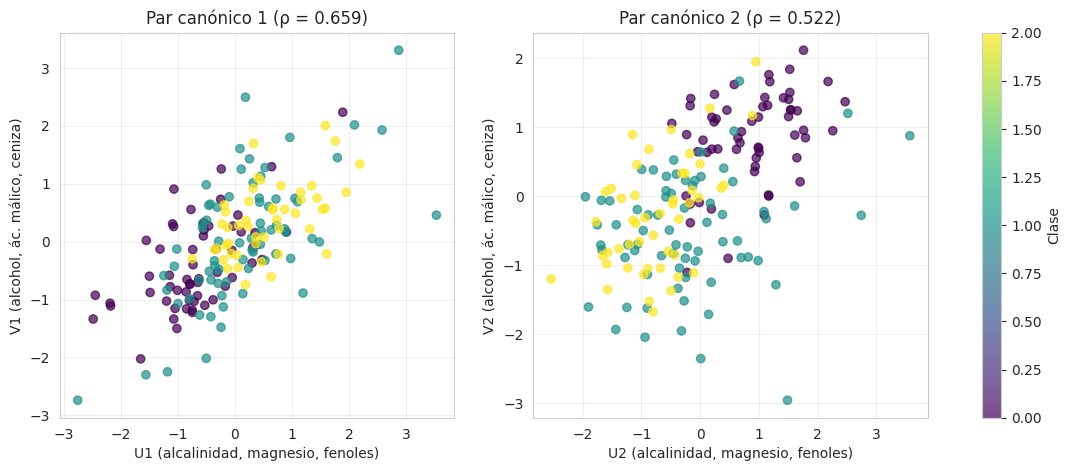

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for k in range(2):
    sc = axes[k].scatter(U_w[:, k], V_w[:, k], c=y_wine, cmap='viridis', alpha=0.7)
    axes[k].set_xlabel(f'U{k+1} (alcalinidad, magnesio, fenoles)')
    axes[k].set_ylabel(f'V{k+1} (alcohol, ác. málico, ceniza)')
    axes[k].set_title(f'Par canónico {k+1} (ρ = {rho_w[k]:.3f})')
    axes[k].grid(True, alpha=0.3)
fig.colorbar(sc, ax=axes, label='Clase')
plt.show()

### 2. Análisis factorial

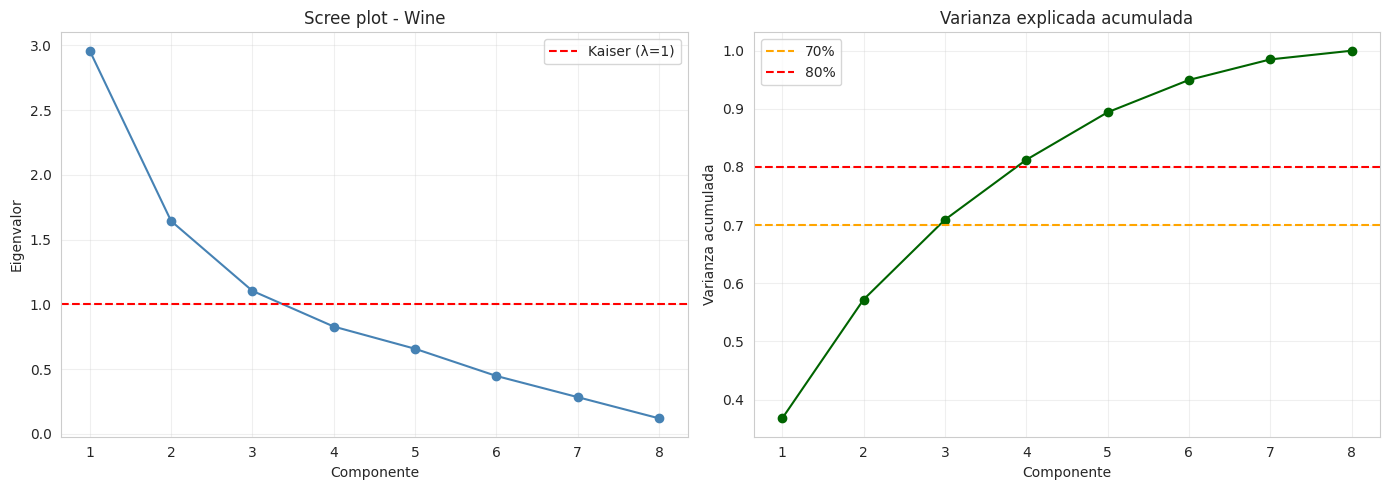

Eigenvalores: [2.958 1.644 1.104 0.829 0.658 0.448 0.284 0.121]
Factores con eigenvalor > 1: 3
Varianza acumulada con 3 factores: 0.709


In [18]:
vars_fa_w = ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash',
             'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols']
X_fa_w = df_wine[vars_fa_w].values
X_fa_w_std = StandardScaler().fit_transform(X_fa_w)

pca_w = PCA().fit(X_fa_w_std)
eig_w = pca_w.explained_variance_
acum_w = np.cumsum(pca_w.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(eig_w)+1), eig_w, 'o-', color='steelblue')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_xlabel('Componente'); axes[0].set_ylabel('Eigenvalor')
axes[0].set_title('Scree plot - Wine'); axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(range(1, len(acum_w)+1), acum_w, 'o-', color='darkgreen')
axes[1].axhline(y=0.7, color='orange', linestyle='--', label='70%')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80%')
axes[1].set_xlabel('Componente'); axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title('Varianza explicada acumulada'); axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

n_fact_w = int(sum(eig_w > 1))
print("Eigenvalores:", np.round(eig_w, 3))
print(f"Factores con eigenvalor > 1: {n_fact_w}")
print(f"Varianza acumulada con {n_fact_w} factores: {acum_w[n_fact_w-1]:.3f}")

Cargas factoriales:
                         F1     F2     F3
alcohol               0.281 -0.216 -0.765
malic_acid           -0.410 -0.258 -0.160
ash                   0.125 -0.911  0.025
alcalinity_of_ash    -0.373 -0.527  0.414
magnesium             0.223 -0.259 -0.230
total_phenols         0.882 -0.028 -0.040
flavanoids            0.981  0.010  0.048
nonflavanoid_phenols -0.547 -0.265  0.088


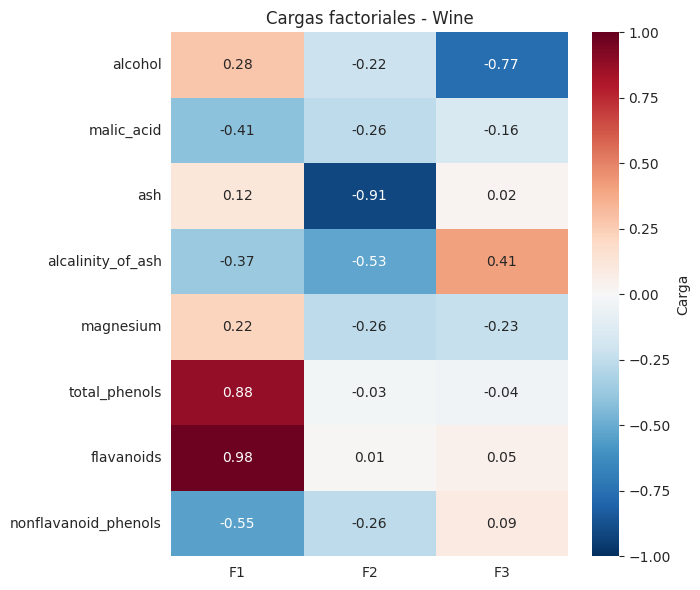


Comunalidades:
alcohol                 0.711
malic_acid              0.260
ash                     0.845
alcalinity_of_ash       0.588
magnesium               0.169
total_phenols           0.781
flavanoids              0.964
nonflavanoid_phenols    0.377
dtype: float64


In [19]:
fa_w = FactorAnalysis(n_components=n_fact_w, random_state=42)
scores_w = fa_w.fit_transform(X_fa_w_std)
cargas_w = pd.DataFrame(fa_w.components_.T, index=vars_fa_w,
                        columns=[f'F{i+1}' for i in range(n_fact_w)])
print("Cargas factoriales:")
print(cargas_w.round(3))

plt.figure(figsize=(7, 6))
sns.heatmap(cargas_w, annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1, fmt='.2f', cbar_kws={'label': 'Carga'})
plt.title('Cargas factoriales - Wine'); plt.tight_layout(); plt.show()

print("\nComunalidades:")
print((cargas_w ** 2).sum(axis=1).round(3))

### Análisis factorial


In [20]:
df_wine['Clase_bin'] = (df_wine['Clase'] == 0).astype(int)
y_bin = df_wine['Clase_bin']

X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(
    X_fa_w_std, y_bin, test_size=0.3, random_state=42, stratify=y_bin)
m_orig_w = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_w, y_tr_w)
acc_o = accuracy_score(y_te_w, m_orig_w.predict(X_te_w))

X_tr_wf, X_te_wf, _, _ = train_test_split(
    scores_w, y_bin, test_size=0.3, random_state=42, stratify=y_bin)
m_fa_w = LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_wf, y_tr_w)
acc_f = accuracy_score(y_te_w, m_fa_w.predict(X_te_wf))

print("=== COMPARACIÓN DE MODELOS ===")
print(f"Variables originales ({X_fa_w.shape[1]} vars): accuracy = {acc_o:.4f}")
print(f"Scores factoriales ({n_fact_w} factores): accuracy = {acc_f:.4f}")
print(f"Reducción de dimensionalidad: {X_fa_w.shape[1]} → {n_fact_w}")

=== COMPARACIÓN DE MODELOS ===
Variables originales (8 vars): accuracy = 0.9444
Scores factoriales (3 factores): accuracy = 0.9074
Reducción de dimensionalidad: 8 → 3


## Interpretación de resultados

 Las correlaciones canónicas son ρ₁ = 0.659 (ρ² = 0.435) y ρ₂ = 0.522 (ρ² = 0.272): el primer par comparte ~43% de varianza y el segundo ~27%, una asociación moderada entre las propiedades del conjunto X (alcalinidad, magnesio, fenoles) y las del conjunto Y (alcohol, ácido málico, ceniza). El primer par está dominado por la alcalinidad de la ceniza (carga 0.99 en U1) y, del lado Y, por la ceniza (0.74): es lo esperable, pues ambas miden el residuo mineral del vino. El segundo par contrasta fenoles totales y magnesio (cargas 0.84 y 0.68 en U2) con alcohol (0.60) y ceniza (0.65) frente a ácido málico (−0.46): vinos más ricos en fenoles tienden a tener mayor grado alcohólico y menos ácido málico.

Del análsis factorial El scree plot y la regla de Kaiser (λ>1) indican 3 factores, que explican 70.9% de la varianza (eigenvalores 2.96, 1.64, 1.10). Interpretación de los factores:

- F1–"Contenido fenólico": flavanoides (0.98) y fenoles totales (0.88), en contraposición con fenoles no flavonoides (−0.55) y ácido málico (−0.41).
- F2–"Mineralidad / ceniza": ceniza (−0.91) y alcalinidad de la ceniza (−0.53); el signo negativo implica que un score alto de F2 corresponde a menor contenido de ceniza.
-F3 – "Alcohol" alcohol (−0.77), con aporte menor de la alcalinidad (0.41).

Las comunalidades son altas para flavanoides, ceniza, fenoles totales y alcohol, pero bajas para magnesio y ácido málico, estas variables aportan información que los 3 factores no capturan.

 Para clasificar la Clase 0 contra el resto, la regresión logística con las 8 variables originales alcanza accuracy = 0.944, y con solo los 3 scores factoriales 0.907. Reducir de 8 a 3 variables, 62% menos, cuesta apenas 3.7 puntos porcentuales de accuracy, a cambio de predictores no correlacionados y más interpretables; no obstante, el modelo con variables originales sigue siendo ligeramente mejor porque los factores descartan la varianza única.